# 4 - Pronóstico de costos

En el notebook 2 encontré que el precio de cada equipo es una combinación fija de sus insumos, en el mismo mes:

- Equipo1 = 0.2X + 0.8Y
- Equipo2 = (X + Y + Z) / 3

En el notebook 3 elegí la regresión lineal para esa relación. Entonces el problema de pronóstico se reduce a proyectar X, Y y Z (con su incertidumbre) y pasar esas proyecciones por el modelo.

In [1]:
import sys
sys.path.append("..")
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

from src import datos

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

mensual = pd.read_csv(datos.PROCESSED / "equipos_mensual.csv", index_col="Date", parse_dates=True)
mensual.index.freq = "MS"
insumos = ["X", "Y", "Z"]
equipos = ["Equipo1", "Equipo2"]
mensual.tail(3)

,X,Y,Z,Equipo1,Equipo2
Date,,,,,
2023-06-01,74.978636,541.775909,2180.738636,449.975909,931.185455
2023-07-01,80.160000,554.357619,2152.011905,460.872381,929.810476
2023-08-01,85.104348,556.303913,2133.021739,461.035217,927.660870


## 1. ¿Qué método proyecta mejor las materias primas?

Hice un backtest con origen móvil: tomé los primeros 6 años para entrenar, pronostiqué los siguientes 12 meses, avancé un mes y repetí. Así evalué cada método en ~80 pronósticos reales fuera de muestra.

Comparé:
- **Naive**: el último valor se repite (caminata aleatoria).
- **Media móvil 3m**: promedio de los últimos 3 meses.
- **Drift**: naive + la tendencia histórica promedio.
- **ARIMA(0,1,1)**: caminata aleatoria con un término MA, que debería captar el efecto del promedio mensual que vi en el notebook 2.

In [2]:
def pronosticar(serie_log, metodo, h):
    if metodo == "naive":
        return np.repeat(serie_log.iloc[-1], h)
    if metodo == "media móvil 3m":
        return np.repeat(serie_log.iloc[-3:].mean(), h)
    if metodo == "drift":
        pendiente = (serie_log.iloc[-1] - serie_log.iloc[0]) / (len(serie_log) - 1)
        return serie_log.iloc[-1] + pendiente * np.arange(1, h + 1)
    if metodo == "ARIMA(0,1,1)":
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return ARIMA(serie_log, order=(0, 1, 1)).fit().forecast(h).values


H = 12
ENTRENAMIENTO_MIN = 72
log_m = np.log(mensual)
origenes = range(ENTRENAMIENTO_MIN, len(log_m) - H + 1)
metodos = ["naive", "media móvil 3m", "drift", "ARIMA(0,1,1)"]

errores = {}
for col in insumos:
    for met in metodos:
        e = []
        for o in origenes:
            pred = np.exp(pronosticar(log_m[col].iloc[:o], met, H))
            real = mensual[col].iloc[o:o + H].values
            e.append(np.abs(pred - real) / real)
        errores[(col, met)] = np.mean(e, axis=0) * 100

mape = pd.DataFrame(errores, index=range(1, H + 1)).T
mape[[1, 3, 6, 12]].round(1)

1     3     6     12
X naive            7.8  15.2  21.9  30.3
  media móvil 3m  11.3  16.8  22.3  29.9
  drift            7.9  15.6  22.9  32.1
  ARIMA(0,1,1)     7.3  15.4  21.9  30.3
Y naive            5.3  11.6  15.9  24.8
  media móvil 3m   8.1  13.1  16.9  26.6
  drift            5.3  11.9  16.7  26.8
  ARIMA(0,1,1)     4.8  11.6  16.1  24.2
Z naive            3.7   7.8  12.3  19.0
  media móvil 3m   5.6   9.2  13.3  19.7
  drift            3.7   8.1  12.9  20.3
  ARIMA(0,1,1)     3.6   7.7  12.3  18.9

MAPE (%) por horizonte en meses.

- El **ARIMA(0,1,1)** es el mejor o empata en casi todos los casos, pero la ventaja sobre el naive es pequeña. Es lo esperable en commodities: sus precios se comportan casi como una caminata aleatoria y no hay mucha estructura que explotar.
- La **media móvil de 3 meses es la peor** en horizontes cortos: al promediar meses pasados reacciona tarde a los cambios.
- El drift empeora a 12 meses: extrapolar la tendencia pasada no ayuda.

Como el ARIMA casi no mejora al naive, para los intervalos no usé tres ARIMA separados: usé una simulación que proyecta los tres insumos juntos y conserva la correlación entre ellos (sección 2).

El error crece rápido con el horizonte (para X pasa de ~7% a 1 mes a ~30% a 12 meses). Por eso más que un número puntual lo importante es el rango.

## 2. Simulación de escenarios

Para tener intervalos generé miles de trayectorias posibles de X, Y y Z (5,000 en las pruebas y 10,000 en el pronóstico final):

- Tomé los retornos mensuales históricos **de los tres insumos al mismo tiempo**, así se conserva la correlación entre ellos (si X sube, Z suele subir también).
- Los tomé en bloques de 3 meses consecutivos (block bootstrap) para conservar la autocorrelación que deja el promedio mensual.
- Les resté su promedio, así el escenario central es "el precio se queda donde está", consistente con lo que ganó en el backtest.

Después pasé cada trayectoria por la fórmula de cada equipo y le sumé el error de la fórmula.

El parámetro `escala` permite ampliar la volatilidad; lo usé en la sección 3.

In [3]:
def pesos_formula(df):
    # regresión lineal elegida en el notebook 3; quito la constante porque no fue significativa (notebook 2)
    modelo1 = sm.OLS(df["Equipo1"], df[["X", "Y"]]).fit()
    modelo2 = sm.OLS(df["Equipo2"], df[["X", "Y", "Z"]]).fit()
    return {"Equipo1": modelo1, "Equipo2": modelo2}


def simular(df, h, n=5000, bloque=3, escala=1.0, semilla=0):
    rng = np.random.default_rng(semilla)

    # Paso 1: retornos mensuales de los insumos, centrados en cero y escalados
    retornos = np.log(df[insumos]).diff().dropna()
    retornos = (retornos - retornos.mean()) * escala
    retornos = retornos.values            # tabla de meses x 3 insumos

    # Paso 2: elijo al azar en qué mes empieza cada bloque de 3 meses
    n_bloques = int(np.ceil(h / bloque))
    inicios = rng.integers(0, len(retornos) - bloque + 1, size=(n, n_bloques))

    # Paso 3: armo cada escenario pegando sus bloques uno tras otro
    pasos = np.zeros((n, h, len(insumos)))
    for i in range(n):
        meses = []
        for inicio in inicios[i]:
            meses.extend(range(inicio, inicio + bloque))
        pasos[i] = retornos[meses[:h]]

    # Paso 4: de retornos a precios, partiendo del último precio conocido
    ultimo_precio = np.log(df[insumos].iloc[-1].values)
    precios = np.exp(ultimo_precio + pasos.cumsum(axis=1))
    sims = {}
    for i, ins in enumerate(insumos):
        sims[ins] = precios[:, :, i]

    # Paso 5: paso cada escenario por la fórmula del equipo y le sumo su error
    for eq, modelo in pesos_formula(df).items():
        precio_equipo = 0
        for insumo in modelo.params.index:
            precio_equipo = precio_equipo + modelo.params[insumo] * sims[insumo]
        ruido = rng.normal(0, np.sqrt(modelo.scale), size=precio_equipo.shape)
        sims[eq] = precio_equipo + ruido
    return sims


sims = simular(mensual, H)
for nombre, valores in sims.items():
    print(nombre, valores.shape)

X (5000, 12)
Y (5000, 12)
Z (5000, 12)
Equipo1 (5000, 12)
Equipo2 (5000, 12)


## 3. ¿Los intervalos son confiables?

Un intervalo de 90% debería contener el valor real ~90% de las veces. Lo revisé con el mismo backtest: en cada origen simulé con los datos disponibles hasta ese momento, calculé el rango P5-P95 y vi si el valor real cayó adentro.

In [4]:
def backtest(escala=1.0, n=2000):
    cobertura = {"Equipo1": [], "Equipo2": []}
    error = {"Equipo1": [], "Equipo2": []}
    ancho = {"Equipo1": [], "Equipo2": []}

    # en cada origen simulo solo con los datos que había hasta ese momento
    for o in origenes:
        s = simular(mensual.iloc[:o], H, n=n, escala=escala, semilla=o)
        for eq in equipos:
            real = mensual[eq].iloc[o:o + H].values
            p5 = np.percentile(s[eq], 5, axis=0)
            p50 = np.percentile(s[eq], 50, axis=0)
            p95 = np.percentile(s[eq], 95, axis=0)

            cobertura[eq].append((real >= p5) & (real <= p95))
            error[eq].append(np.abs(p50 - real) / real)
            ancho[eq].append((p95 - p5) / p50)

    # promedio de todos los orígenes, por cada mes adelante (1 a 12)
    meses = range(1, H + 1)
    tabla_cobertura = pd.DataFrame(index=meses)
    tabla_error = pd.DataFrame(index=meses)
    tabla_ancho = pd.DataFrame(index=meses)
    for eq in equipos:
        tabla_cobertura[eq] = np.mean(cobertura[eq], axis=0) * 100
        tabla_error[eq] = np.mean(error[eq], axis=0) * 100
        tabla_ancho[eq] = np.mean(ancho[eq], axis=0) * 100

    resumen = pd.concat(
        [tabla_cobertura, tabla_error, tabla_ancho], axis=1,
        keys=["cobertura 90% (%)", "MAPE P50 (%)", "ancho P5-P95 (% del P50)"],
    )
    resumen.index.name = "meses adelante"
    return resumen


sin_ajuste = backtest(escala=1.0)
sin_ajuste["cobertura 90% (%)"].loc[[1, 3, 6, 12]].round(1)

,Equipo1,Equipo2
meses adelante,,
1,84.0,79.0
3,80.2,75.3
6,79.0,75.3
12,81.5,70.4


El intervalo de "90%" en realidad cubre entre 70% y 85%: se queda corto. Revisé por qué:

In [5]:
ret = np.log(mensual[insumos]).diff().dropna()
pd.DataFrame({
    "2010-2015": ret.loc[:"2015"].std(),
    "2016-2023": ret.loc["2016":].std(),
}).mul(100).round(1)

,2010-2015,2016-2023
X,7.3,10.0
Y,4.6,7.0
Z,4.5,4.6


La volatilidad mensual de X y Y subió bastante después de 2016 (COVID en 2020, el boom de commodities de 2021-2022). Los primeros orígenes del backtest solo conocían el periodo tranquilo, por eso sus rangos quedan angostos.

Probé ampliar la volatilidad simulada con un factor y vi con cuál la cobertura se acerca a 90%:

In [6]:
cobertura_por_escala = {}
for esc in [1.0, 1.15, 1.3, 1.45]:
    cob = backtest(escala=esc)["cobertura 90% (%)"]
    cobertura_por_escala[esc] = cob.mean()

pd.DataFrame(cobertura_por_escala).T.round(1).rename_axis("escala")

,Equipo1,Equipo2
escala,,
1.00,80.7,74.9
1.15,85.1,81.6
1.30,88.9,86.5
1.45,92.1,90.0


Con **1.3** la cobertura promedio sube a ~87-89%, cerca del objetivo. Con 1.45 llegaría a 90-92%, pero los rangos se vuelven tan anchos que pierden utilidad para presupuestar, así que me quedé con 1.3 como punto medio.

Ojo: el factor lo elegí con el mismo backtest, así que hay que revisarlo conforme lleguen datos nuevos.

In [7]:
ESCALA = 1.3
resumen = backtest(escala=ESCALA)
resumen.round(1)

cobertura 90% (%)         MAPE P50 (%)          \
                         Equipo1 Equipo2      Equipo1 Equipo2   
meses adelante                                                  
1                           90.1    93.8          5.3     3.9   
2                           88.9    87.7          9.2     6.6   
3                           92.6    90.1         11.9     8.5   
4                           91.4    86.4         13.7     9.7   
5                           92.6    85.2         14.7    11.2   
6                           92.6    85.2         15.7    12.6   
7                           90.1    82.7         17.0    14.0   
8                           86.4    82.7         18.5    15.5   
9                           85.2    85.2         19.9    16.8   
10                          85.2    87.7         21.3    18.1   
11                          85.2    87.7         23.1    19.3   
12                          86.4    84.0         24.7    20.4   

               ancho P5-P95 (% del P50)          
                                Equipo1 Equipo2  
meses adelante                                   
1                                  25.6    16.6  
2                                  43.2    25.5  
3                                  54.7    32.4  
4                                  60.7    36.6  
5                                  70.9    42.1  
6                                  79.6    46.9  
7                                  83.7    49.8  
8                                  91.3    53.8  
9                                  98.0    57.7  
10                                102.1    60.1  
11                                108.8    63.6  
12                                114.4    66.9

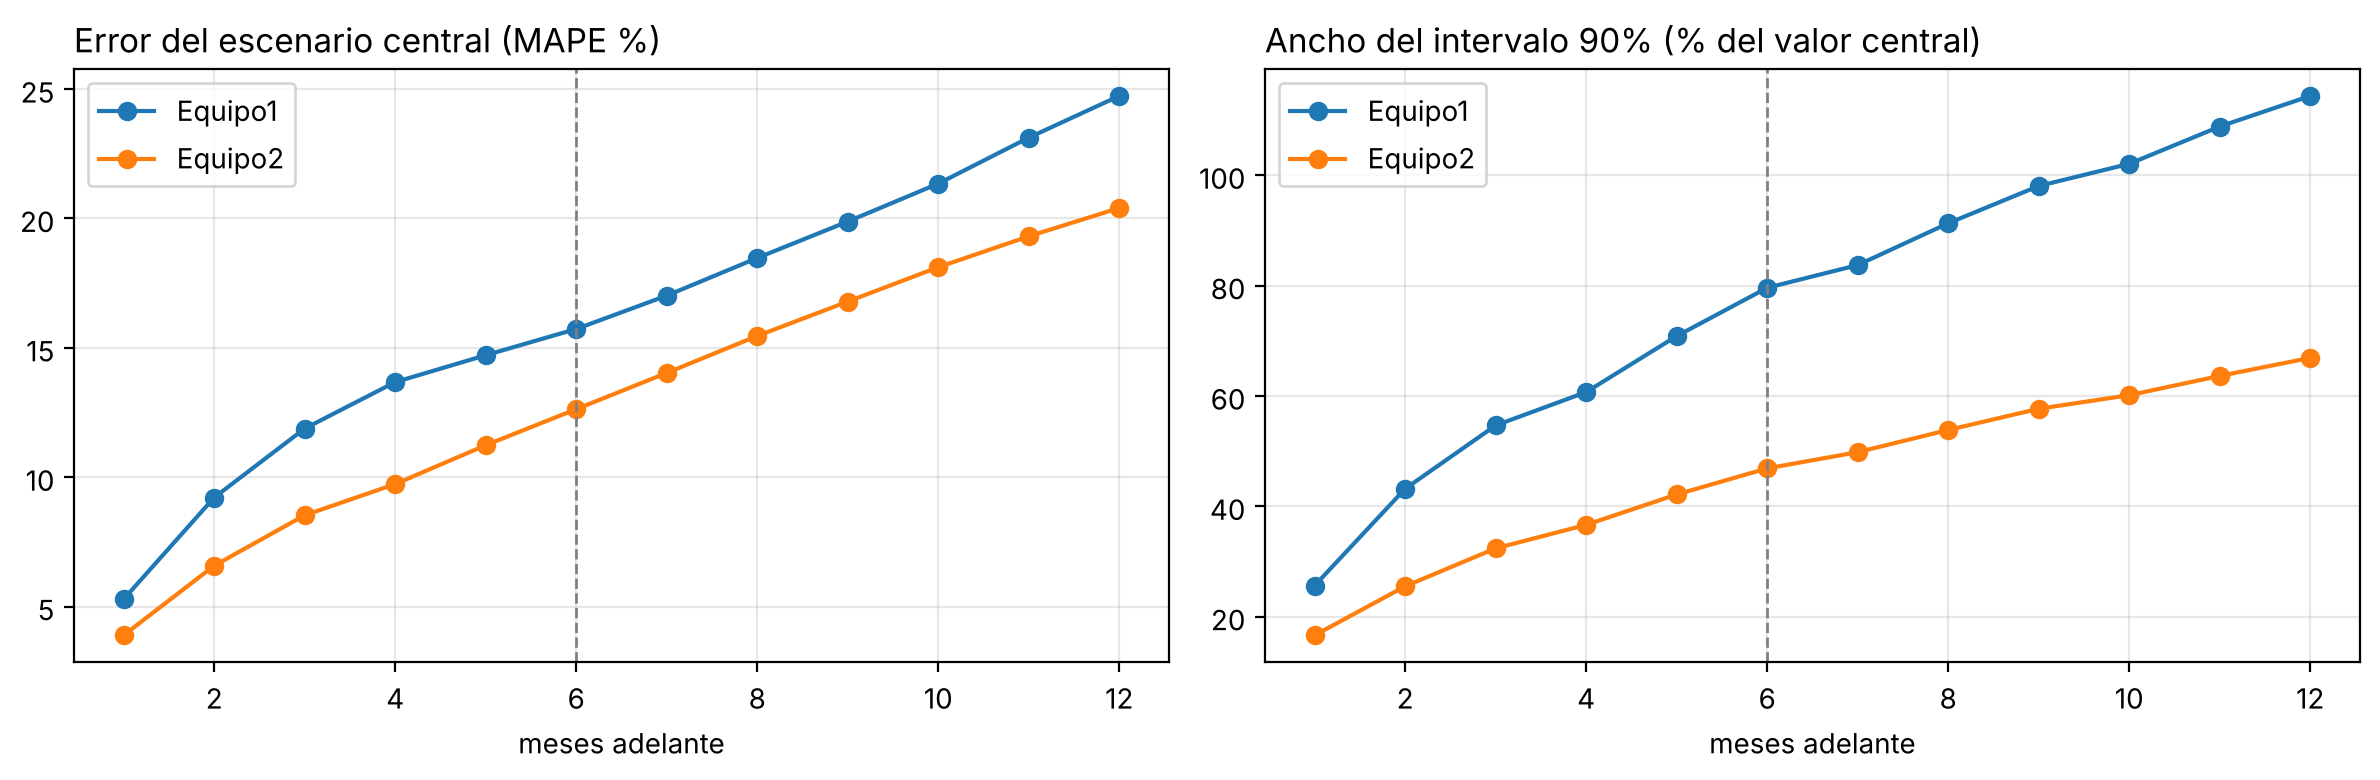

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for eq in equipos:
    axs[0].plot(resumen.index, resumen[("MAPE P50 (%)", eq)], marker="o", label=eq)
    axs[1].plot(resumen.index, resumen[("ancho P5-P95 (% del P50)", eq)], marker="o", label=eq)
axs[0].set_title("Error del escenario central (MAPE %)", loc="left")
axs[1].set_title("Ancho del intervalo 90% (% del valor central)", loc="left")
for ax in axs:
    ax.set_xlabel("meses adelante")
    ax.axvline(6, color="gray", ls="--", lw=1)
    ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/04_error_vs_horizonte.png", dpi=120)
plt.show()

## 4. Horizonte de pronóstico

El error crece con el horizonte de forma gradual, como en una caminata aleatoria: no hay un mes en que el modelo "se rompa", pero sí un punto en que el rango deja de ser útil para presupuestar.

Mi criterio: que el error típico del escenario central se mantenga en ~15% o menos, que es un nivel de contingencia razonable para un presupuesto de obra.

- **1 a 3 meses**: error de 4-12%. Sirve para decisiones de compra concretas.
- **6 meses**: error de 13-16%. El rango de 90% es amplio, sobre todo en Equipo1, porque Y es el insumo más volátil. Aun así sirve para fijar presupuesto con contingencia. **Este es mi horizonte principal.**
- **12 meses**: error de 20-25% y rangos de ±35% (Equipo2) a ±55% (Equipo1). Lo presenté como escenario, no como pronóstico.

Como no hay rezagos, esperar no mejora el pronóstico. Lo que sí lo mejora es **actualizarlo cada mes** con el dato nuevo: el error a 1 mes es unas 3 veces menor que a 6.

## 5. Pronóstico final

Último dato: agosto 2023. Proyecté septiembre 2023 a agosto 2024.

In [9]:
sims = simular(mensual, H, n=10000, escala=ESCALA, semilla=42)
fechas = pd.date_range(mensual.index[-1] + pd.offsets.MonthBegin(), periods=H, freq="MS")

tablas = {}
for col in equipos + insumos:
    p = np.percentile(sims[col], [5, 25, 50, 75, 95], axis=0)
    tablas[col] = pd.DataFrame(p.T, index=fechas, columns=["P5", "P25", "P50", "P75", "P95"])

pronostico = pd.concat(tablas, axis=1)
pronostico.to_csv(datos.PROCESSED / "pronostico_12m.csv")
pronostico[equipos].head(6).round(1)

Equipo1                             Equipo2                        \
                P5    P25    P50    P75    P95      P5    P25    P50     P75   
2023-09-01   409.0  442.9  458.4  477.8  527.7   844.9  892.3  923.2   963.7   
2023-10-01   380.8  421.9  456.1  494.2  582.9   805.5  870.3  930.3   988.2   
2023-11-01   367.1  411.1  456.4  508.3  623.6   767.3  846.3  920.3  1003.4   
2023-12-01   350.5  405.4  454.9  514.3  639.5   749.7  847.4  925.1  1012.5   
2024-01-01   334.5  397.3  454.4  525.7  671.3   728.6  836.8  926.8  1025.3   
2024-02-01   319.1  390.6  452.1  533.3  699.0   705.1  829.2  929.3  1037.9   

                    
               P95  
2023-09-01  1015.1  
2023-10-01  1074.0  
2023-11-01  1110.5  
2023-12-01  1139.6  
2024-01-01  1178.5  
2024-02-01  1214.7

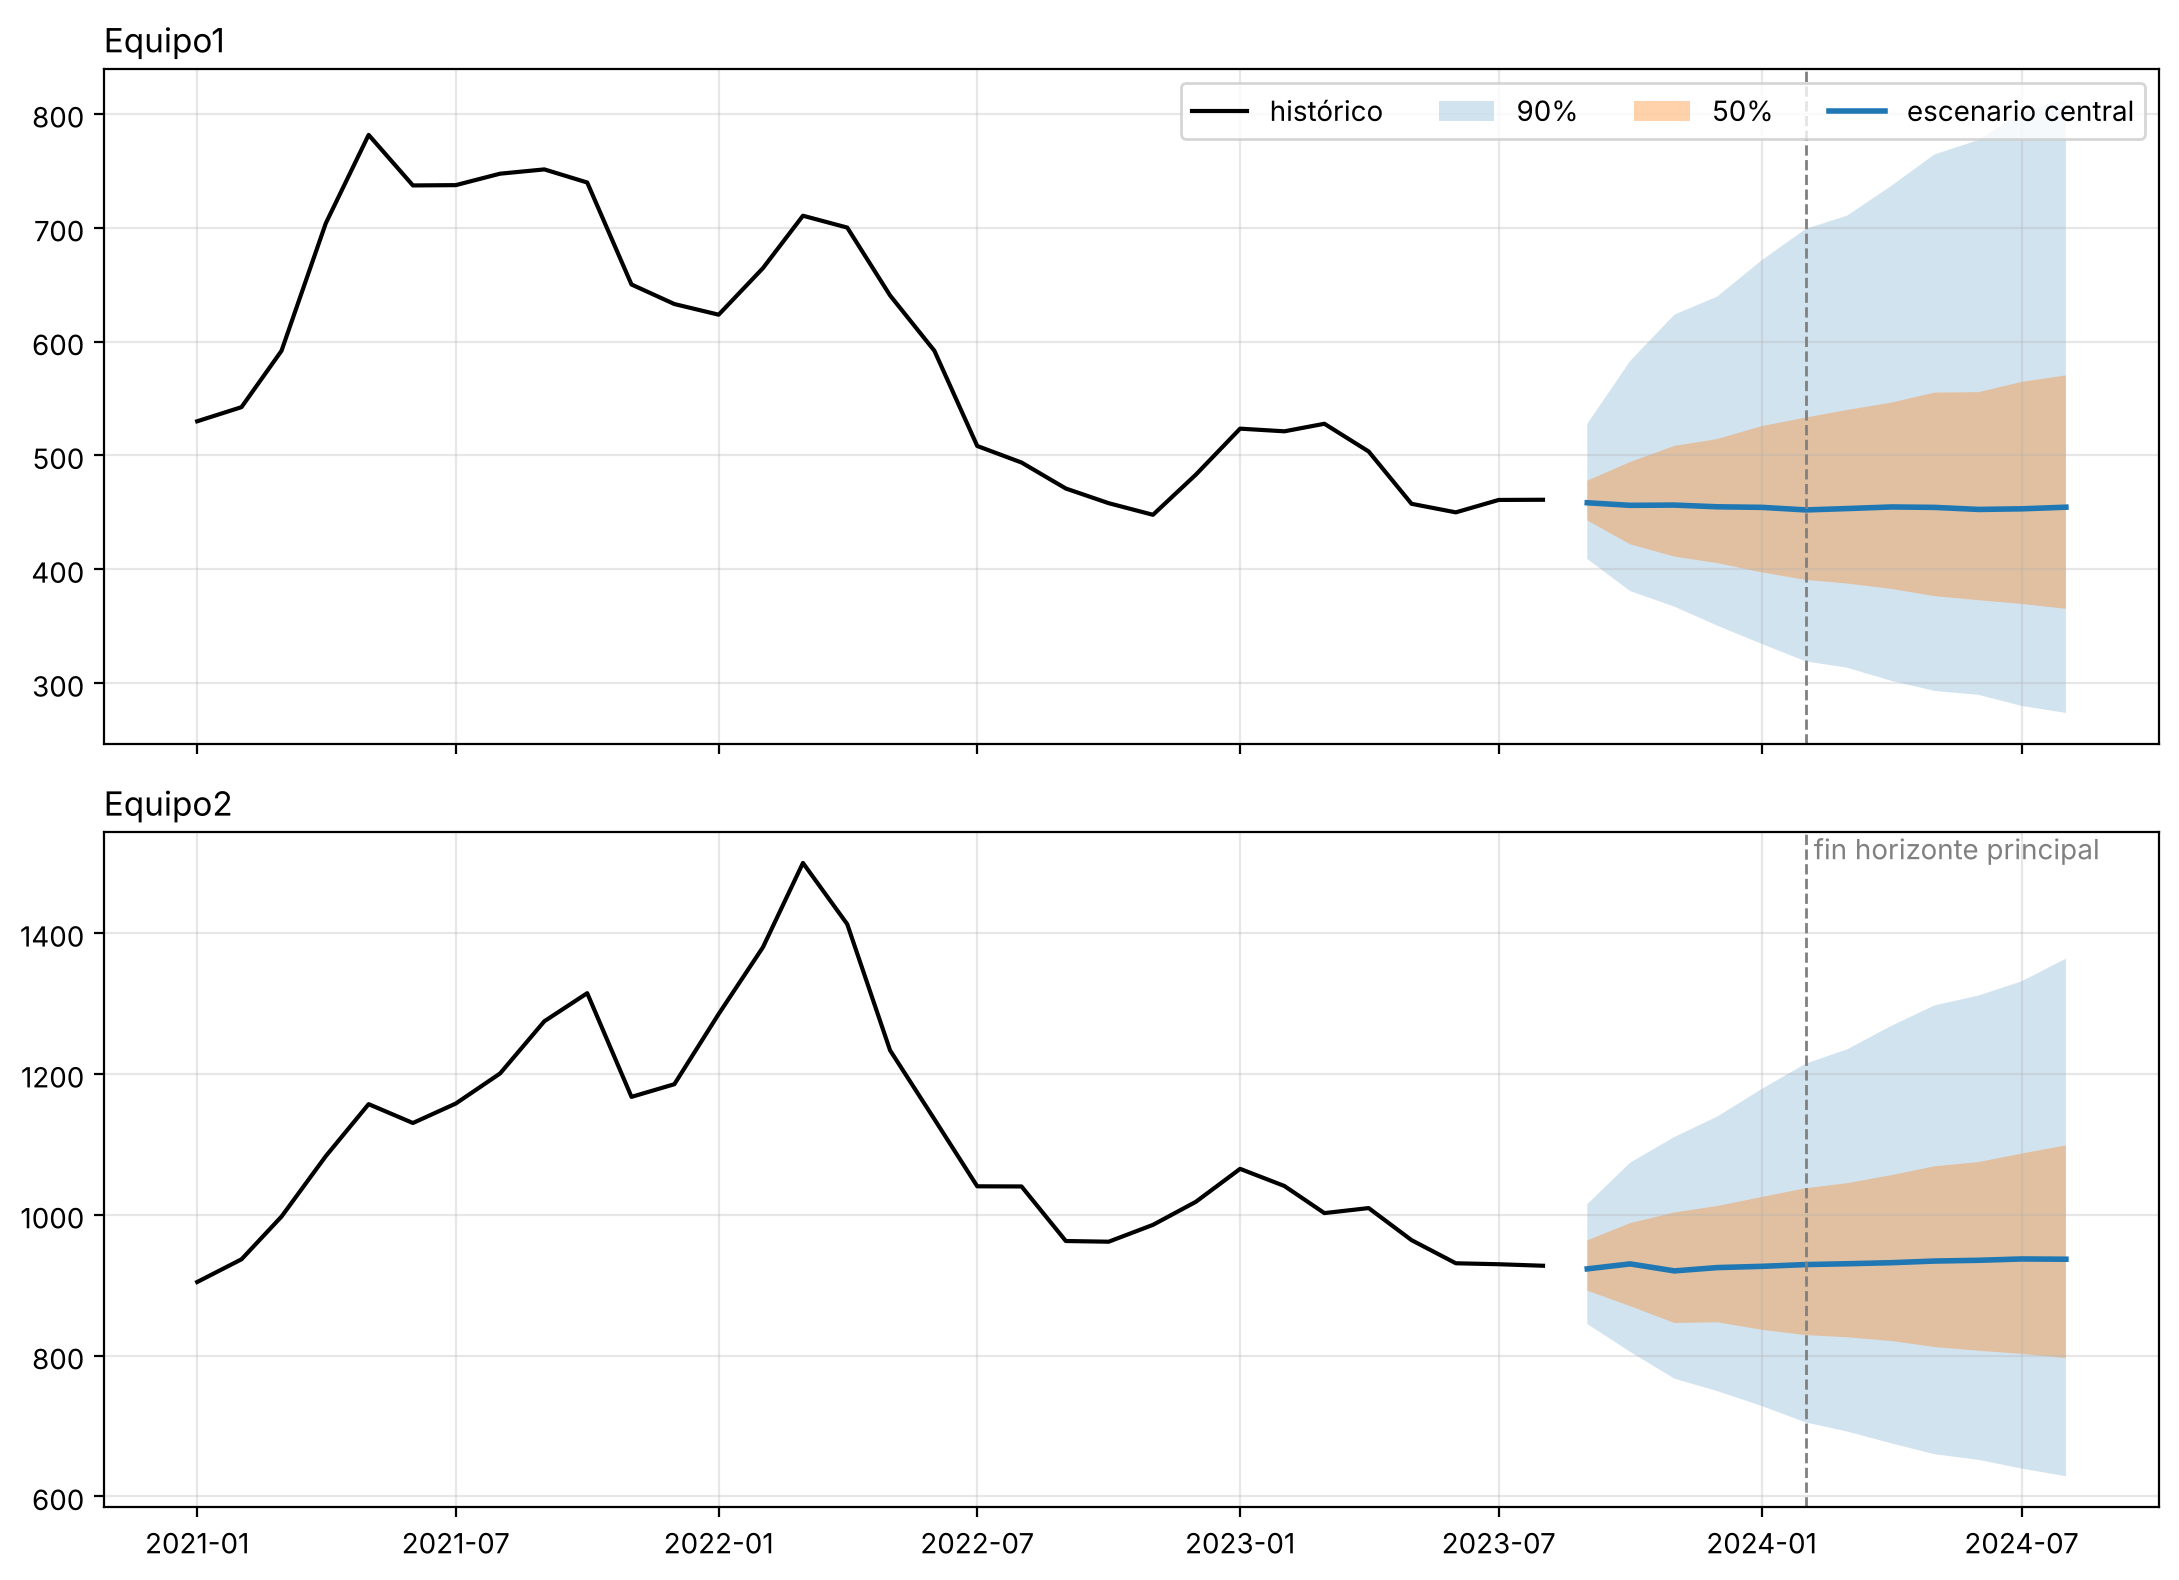

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ax, eq in zip(axs, equipos):
    hist = mensual[eq].loc["2021":]
    t = tablas[eq]
    ax.plot(hist, color="black", lw=1.5, label="histórico")
    ax.fill_between(t.index, t["P5"], t["P95"], alpha=0.2, label="90%")
    ax.fill_between(t.index, t["P25"], t["P75"], alpha=0.35, label="50%")
    ax.plot(t["P50"], lw=2, label="escenario central")
    ax.axvline(fechas[5], color="gray", ls="--", lw=1)
    ax.set_title(eq, loc="left")
axs[0].legend(loc="upper right", ncol=4)
axs[1].text(fechas[5], axs[1].get_ylim()[1], " fin horizonte principal", va="top", color="gray")
plt.tight_layout()
plt.savefig("../reports/figures/04_pronostico.png", dpi=120)
plt.show()

## 6. Revisión con datos reales de X

El archivo `X.csv` trae datos hasta abril 2024, más allá del histórico de equipos. Los usé para ver dónde cayó X realmente frente a lo que proyecté.

In [11]:
x_real = datos.leer_x().loc["2023-09":"2024-03"].resample("MS").mean()

check = tablas["X"].loc[x_real.index, ["P5", "P50", "P95"]].copy()
check["real"] = x_real
check["dentro del 90%"] = (check["real"] >= check["P5"]) & (check["real"] <= check["P95"])
check.round(1)

,P5,P50,P95,real,dentro del 90%
Date,,,,,
2023-09-01,68.8,86.2,99.2,92.6,True
2023-10-01,62.5,85.7,108.8,88.7,True
2023-11-01,56.4,85.5,115.9,82.0,True
2023-12-01,52.0,86.3,122.8,77.3,True
2024-01-01,47.6,86.6,130.4,79.1,True
2024-02-01,45.1,87.1,135.2,81.7,True
2024-03-01,43.4,86.8,140.2,84.5,True


Todos los meses reales de X caen dentro del rango proyectado. Es una sola trayectoria, así que no prueba nada por sí sola, pero es consistente con la cobertura del backtest.

## Resumen

- Proyecté las materias primas con simulación por bloques de sus retornos conjuntos y pasé las trayectorias por la fórmula de cada equipo.
- Ningún método le gana claramente a "el precio se queda donde está". Lo valioso del modelo es el **rango** y la **fórmula**, que permite hacer escenarios ("¿qué pasa si Y sube 10%?").
- Horizonte principal: **6 meses**, actualizando cada mes. Los meses 7-12 son escenarios.
- Calibré los intervalos con el backtest (factor 1.3 sobre la volatilidad histórica): el rango de 90% cubre ~87-89% de los casos reales.